In [1]:
#Question 3.1
import re
import zipfile
import unicodedata
import warnings
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [2]:
rows = []
with zipfile.ZipFile("research_corpus.zip") as z:
    names = sorted([n for n in z.namelist() if n.endswith(".txt")],
                   key=lambda n: int(re.findall(r"\d+", n.split("/")[-1])[0]))
    for n in names:
        rows.append({"article_id": int(re.findall(r"\d+", n.split("/")[-1])[0]),
                     "filename": n.split("/")[-1],
                     "text": z.read(n).decode("utf-8", errors="ignore")})

corpus = pd.DataFrame(rows)
corpus["n_chars"] = corpus.text.str.len()
corpus["n_words"] = corpus.text.str.split().str.len()
corpus["preview"] = corpus.text.str.replace(r"\s+", " ", regex=True).str[:90]
corpus[["article_id", "filename", "n_chars", "n_words", "preview"]]

,article_id,filename,n_chars,n_words,preview
0,1,research_1.txt,38598,5602,The purposes of this article are to position m...
1,2,research_2.txt,16279,2416,"Now I see it, now I don’t: researcher’s positi..."
2,3,research_3.txt,26521,3828,DEVELOPMENTAL RESEARCH: STUDIES OF INSTRUCTION...
3,4,research_4.txt,39072,5922,Abstract Cronbach’s alpha is a statistic commo...
4,5,research_5.txt,27142,4027,Denzin’s Paradigm Shift: Revisiting Triangulat...


In [3]:
#Question 3.2
doc_stop = {"article", "articles", "paper", "papers", "study", "studies", "research", "researcher", "researchers",
            "journal", "volume", "issue", "figure", "table", "chapter", "section", "university", "press", "sage",
            "publications", "also", "may", "one", "two", "would", "could", "many", "much", "often", "thus",
            "however", "like", "al", "et"}
STOP = set(ENGLISH_STOP_WORDS) | doc_stop
KEEP = {"series", "bias", "analysis", "basis", "hypothesis", "economics", "statistics", "dynamics", "physics",
        "process", "class", "status", "focus", "business", "consensus", "thesis", "synthesis", "emphasis", "crisis"}
IRREG = {"analyses": "analysis", "hypotheses": "hypothesis", "theses": "thesis", "bases": "basis"}

def lemma(w):
    if w in KEEP or len(w) <= 3:
        return w
    if w in IRREG:
        return IRREG[w]
    if w.endswith("ies") and len(w) > 4:
        return w[:-3] + "y"
    if w.endswith(("sses", "shes", "ches", "xes", "zes")):
        return w[:-2]
    if w.endswith("s") and not w.endswith(("ss", "us", "is", "ics")):
        return w[:-1]
    return w

def readable(text):
    t = re.sub(r"(\w)-\s*\n\s*(\w)", r"\1\2", text)
    t = re.sub(r"(https?://\S+|www\.\S+)", " ", t)
    t = re.sub(r"\S+@\S+\.\S+", " ", t)
    t = re.sub(r"\((?:[^()]{0,120}?)\b(?:1[89]\d{2}|20[0-2]\d)[a-z]?(?:[^()]{0,60})\)", "", t)
    t = re.sub(r"\[\s*\d+(?:\s*[,-]\s*\d+)*\s*\]", "", t)
    t = re.sub(r"(?<=[a-z\.\"\u201d,;])\d{1,2}(?:,\s*\d{1,2})*(?=\s|$)", "", t)
    t = t.replace("\u2019", "'").replace("\u2018", "'").replace("\u201c", '"').replace("\u201d", '"')
    t = re.sub(r"\s+", " ", t)
    return re.sub(r"\s+([,.;:])", r"\1", t).strip()

def to_tokens(text):
    t = text.replace("\u2013", "-").replace("\u2014", "-")
    t = unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode("ascii").lower()
    t = t.replace("-", " ").replace("/", " ")
    t = re.sub(r"[^a-z\s]", " ", t)
    toks = [lemma(w) for w in t.split() if len(w) >= 3 and w not in STOP]
    return [w for w in toks if w not in STOP and len(w) >= 3]

 as offering an attractive philosophical partner for mixed methods research, and to provide a frame  research, to present pragmatism

CLEAN: purpose position mixed method mixed synonym natural complement traditional qualitative quantitative present pragmatism offering attractive philosophical partner mixed method provide framework designing conducting mixed method doing briefly review paradigm war incompatibility thesis commonality quant


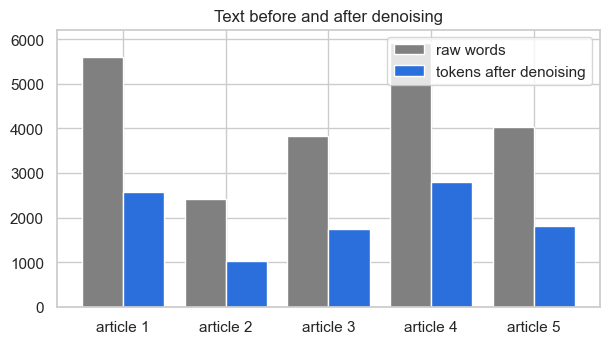

,article_id,n_words,n_tokens
0,1,5602,2578
1,2,2416,1031
2,3,3828,1755
3,4,5922,2804
4,5,4027,1813


In [4]:
corpus["readable"] = corpus.text.apply(readable)
corpus["tokens"] = corpus.readable.apply(to_tokens)
corpus["clean"] = corpus.tokens.apply(" ".join)
corpus["n_tokens"] = corpus.tokens.apply(len)

print("RAW  :", corpus.text[0][:300].replace("\n", " "), "\n")
print("CLEAN:", corpus.clean[0][:300])

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(corpus))
ax.bar(x - 0.2, corpus.n_words, 0.4, color="grey", label="raw words")
ax.bar(x + 0.2, corpus.n_tokens, 0.4, color="#2a6fdb", label="tokens after denoising")
ax.set_xticks(x)
ax.set_xticklabels([f"article {i}" for i in corpus.article_id])
ax.set_title("Text before and after denoising")
ax.legend()
plt.show()
corpus[["article_id", "n_words", "n_tokens"]]

In [5]:
#Question 3.3
SENT_SPLIT = re.compile(r"(?<=[.!?])\s+(?=[A-Z\"'(])")

def sentences(text, min_words=8, max_words=60):
    out, seen = [], set()
    for s in SENT_SPLIT.split(text):
        n = len(s.split())
        key = s.strip().lower()
        if min_words <= n <= max_words and re.search(r"[a-z]{3}", s) and "keywords:" not in key and key not in seen:
            seen.add(key)
            out.append(s.strip())
    return out

In [6]:
sents1 = sentences(corpus.readable[0])
clean1 = [" ".join(to_tokens(s)) for s in sents1]
keep = [i for i, c in enumerate(clean1) if len(c.split()) >= 3]
sents1 = [sents1[i] for i in keep]
clean1 = [clean1[i] for i in keep]

tf1 = TfidfVectorizer()
M1 = tf1.fit_transform(clean1)
sim1 = cosine_similarity(M1)
np.fill_diagonal(sim1, 0)
graph = nx.from_numpy_array(sim1)
pr = nx.pagerank(graph, max_iter=200)
scores1 = np.array([pr[i] for i in range(len(sents1))])
top_idx = sorted(np.argsort(scores1)[::-1][:5])

print(len(sents1), "sentences in article 1\n")
print("SUMMARY OF ARTICLE 1\n")
for i in top_idx:
    print("-", sents1[i], "\n")

69 sentences in article 1

SUMMARY OF ARTICLE 1

- The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research. 

- Both sets of purists view their paradigms as the ideal for research, and, implicitly if not explicitly, they advocate the incompatibility thesis, which posits that qualitative and quantitative research paradigms, including their associated methods, cannot and should not be mixed. 

- We hope the field will move beyond quantitative versus qualitative research arguments because, as recognized by mixed methods research, both quantitative and qualitative research are important and useful. 

- Mixed methods research as the third research paradigm can also help bridge the schism between q

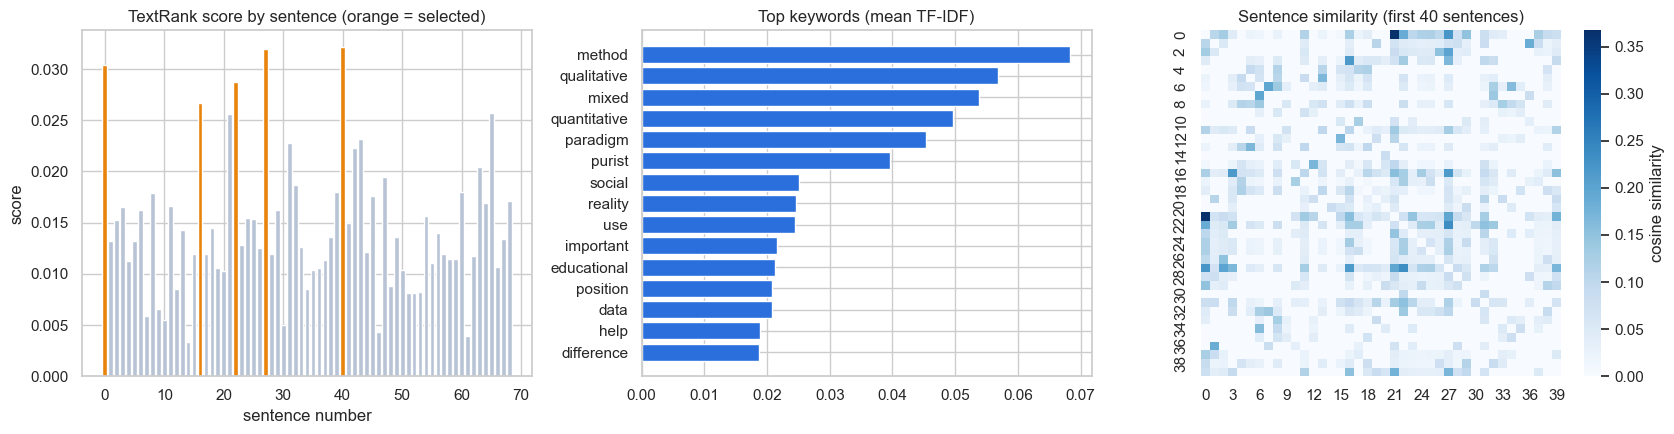

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].bar(range(len(scores1)), scores1, color=["#e8830c" if i in top_idx else "#b8c4d6" for i in range(len(scores1))])
ax[0].set_title("TextRank score by sentence (orange = selected)")
ax[0].set_xlabel("sentence number")
ax[0].set_ylabel("score")

mean_tfidf = np.asarray(M1.mean(axis=0)).ravel()
terms1 = np.array(tf1.get_feature_names_out())
top_terms = np.argsort(mean_tfidf)[::-1][:15][::-1]
ax[1].barh(terms1[top_terms], mean_tfidf[top_terms], color="#2a6fdb")
ax[1].set_title("Top keywords (mean TF-IDF)")

sns.heatmap(sim1[:40, :40], cmap="Blues", ax=ax[2], cbar_kws={"label": "cosine similarity"})
ax[2].set_title("Sentence similarity (first 40 sentences)")
plt.tight_layout()
plt.show()

In [8]:
#Question 3.4
rest = corpus[corpus.article_id != corpus.article_id.min()].reset_index(drop=True)

recs = []
for _, r in rest.iterrows():
    for s in sentences(r.readable):
        c = " ".join(to_tokens(s))
        if len(c.split()) >= 3:
            recs.append({"article_id": r.article_id, "sentence": s, "clean": c})
S = pd.DataFrame(recs)
S.groupby("article_id").size()

article_id
2     48
3    145
4    161
5    152
dtype: int64

In [9]:
tf2 = TfidfVectorizer()
M2 = tf2.fit_transform(S.clean)
centroid = np.asarray(M2.mean(axis=0))
rel = cosine_similarity(M2, centroid).ravel()
simm = cosine_similarity(M2)

def mmr(rel, simm, groups, k=8, lam=0.7, cap=2):
    chosen = [int(np.argmax(rel))]
    while len(chosen) < k:
        cand = [i for i in range(len(rel))
                if i not in chosen and sum(groups[j] == groups[i] for j in chosen) < cap]
        score = [lam * rel[i] - (1 - lam) * simm[i, chosen].max() for i in cand]
        chosen.append(cand[int(np.argmax(score))])
    return chosen

picked = mmr(rel, simm, S.article_id.values, k=8)

print("AGGREGATE SUMMARY OF ARTICLES 2 TO 5\n")
for i in picked:
    print(f"(article {S.article_id[i]}) {S.sentence[i]}\n")

AGGREGATE SUMMARY OF ARTICLES 2 TO 5

(article 5) A case study design with at least two data collection methods is one example of methodological triangulation.

(article 4) The Use of Cronbach's Alpha in Science Education Studies It is common to see the reliability of instruments used in published science education studies framed in terms of a statistic known as Cronbach's alpha.

(article 4) However, the literature also includes reports of the development of tests of student knowledge and understanding that cite Cronbach's alpha as an indicator of instrument quality.

(article 3) The second type of developmental study is oriented toward a general analysis of design, development, or evaluation processes, addressed either as a whole or in terms of a particular component.

(article 5) Qualitative Research and Triangulation The application of triangulation (multiple sources of data) can enhance the reliability of the study results and enable one to saturate the data.

(article 3) Other st

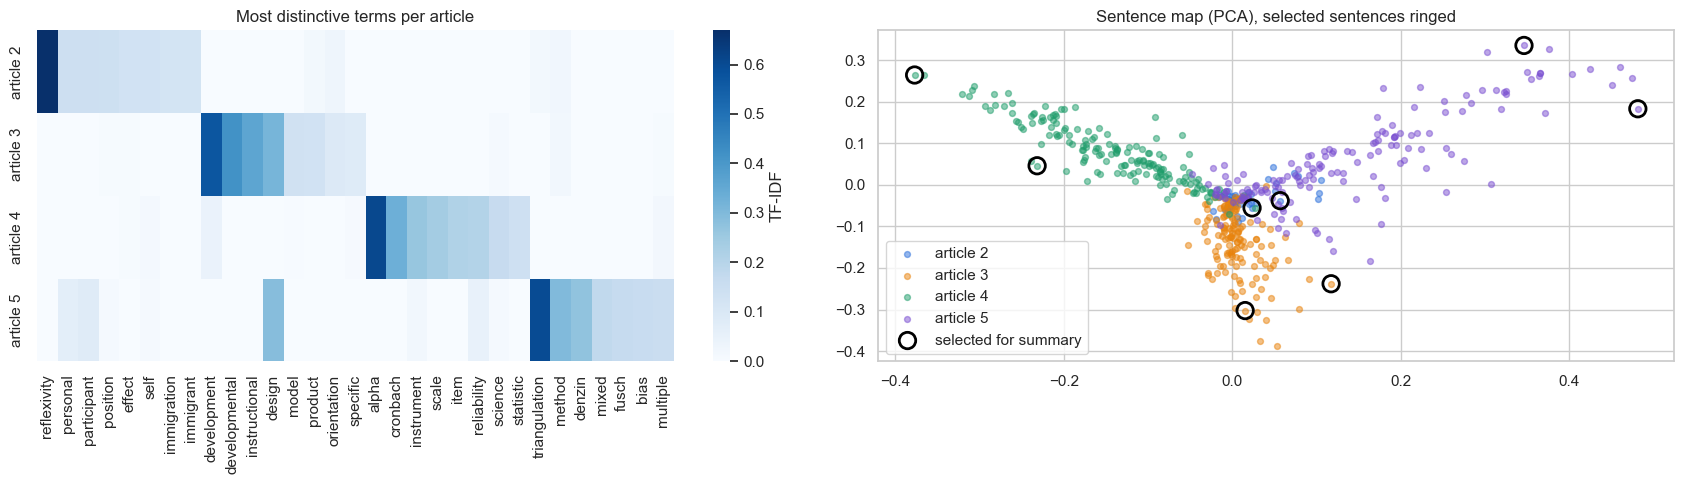

In [10]:
tf_doc = TfidfVectorizer(max_df=0.8)
D = tf_doc.fit_transform(rest.clean)
dterms = np.array(tf_doc.get_feature_names_out())
top_by_doc = [np.argsort(D[i].toarray().ravel())[::-1][:8] for i in range(D.shape[0])]
union = list(dict.fromkeys(dterms[j] for idx in top_by_doc for j in idx))
heat = pd.DataFrame(D.toarray(), columns=dterms, index=[f"article {a}" for a in rest.article_id])[union]

fig, ax = plt.subplots(1, 2, figsize=(17, 5))
sns.heatmap(heat, cmap="Blues", xticklabels=True, ax=ax[0], cbar_kws={"label": "TF-IDF"})
ax[0].set_title("Most distinctive terms per article")
ax[0].tick_params(axis="x", rotation=90)

xy = PCA(n_components=2, random_state=0).fit_transform(M2.toarray())
for a, c in zip(sorted(S.article_id.unique()), ["#2a6fdb", "#e8830c", "#1f9d6b", "#7a4fd1"]):
    m = (S.article_id == a).values
    ax[1].scatter(xy[m, 0], xy[m, 1], s=18, alpha=0.5, color=c, label=f"article {a}")
ax[1].scatter(xy[picked, 0], xy[picked, 1], s=140, facecolors="none", edgecolors="black", linewidths=2, label="selected for summary")
ax[1].set_title("Sentence map (PCA), selected sentences ringed")
ax[1].legend()
plt.tight_layout()
plt.show()

In [14]:
#Question 4.1
CHUNK = 80
recs = []
for _, r in corpus.iterrows():
    toks = r.tokens
    for start in range(0, len(toks) - CHUNK // 2, CHUNK):
        piece = toks[start:start + CHUNK]
        if len(piece) >= CHUNK // 2:
            recs.append({"article_id": r.article_id, "chunk": " ".join(piece)})
chunks = pd.DataFrame(recs)

cv = CountVectorizer(min_df=2, max_df=0.7)
dtm = cv.fit_transform(chunks.chunk)
vocab = np.array(cv.get_feature_names_out())
print(chunks.shape, dtm.shape)
chunks.groupby("article_id").size()

(125, 2) (125, 1325)


article_id
1    32
2    13
3    22
4    35
5    23
dtype: int64

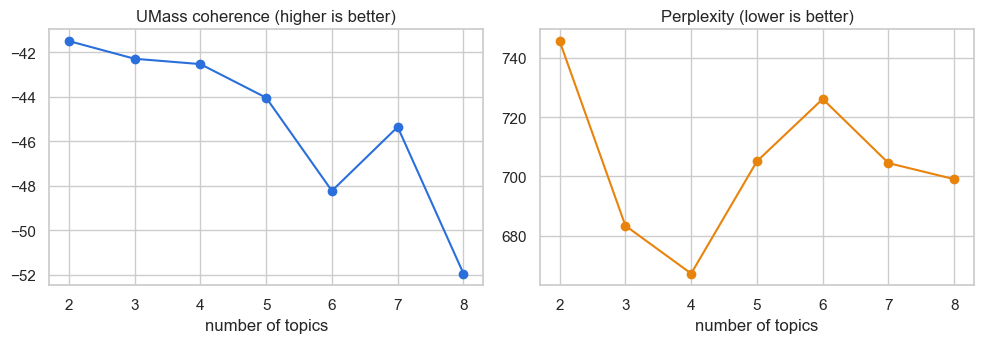

,k,perplexity,umass
0,2,745.71,-41.51
1,3,683.34,-42.30
2,4,667.18,-42.54
3,5,705.10,-44.05
4,6,726.13,-48.23
5,7,704.48,-45.36
6,8,699.05,-51.94


In [15]:
binary = (dtm > 0).astype(int).tocsc()
co = (binary.T @ binary).toarray()
dfreq = np.asarray(binary.sum(axis=0)).ravel()

def umass(lda, topn=10):
    scores = []
    for comp in lda.components_:
        idx = np.argsort(comp)[::-1][:topn]
        s = 0
        for i in range(1, len(idx)):
            for j in range(i):
                s += np.log((co[idx[i], idx[j]] + 1) / dfreq[idx[j]])
        scores.append(s)
    return np.mean(scores)

scan = []
for k in range(2, 9):
    m = LatentDirichletAllocation(n_components=k, learning_method="batch", max_iter=60, random_state=42).fit(dtm)
    scan.append({"k": k, "perplexity": m.perplexity(dtm), "umass": umass(m)})
scan = pd.DataFrame(scan)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(scan.k, scan.umass, "o-", color="#2a6fdb")
ax[0].set_title("UMass coherence (higher is better)")
ax[0].set_xlabel("number of topics")
ax[1].plot(scan.k, scan.perplexity, "o-", color="#e8830c")
ax[1].set_title("Perplexity (lower is better)")
ax[1].set_xlabel("number of topics")
plt.tight_layout()
plt.show()
scan.round(2)

In [16]:
N_TOPICS = 5
lda = LatentDirichletAllocation(n_components=N_TOPICS, learning_method="batch", max_iter=100, random_state=42).fit(dtm)
topic_word = lda.components_ / lda.components_.sum(axis=1, keepdims=True)
topic_names = [f"Topic {t + 1}" for t in range(N_TOPICS)]

topic_table = pd.DataFrame({
    topic_names[t]: [f"{vocab[i]} ({topic_word[t, i]:.3f})" for i in np.argsort(topic_word[t])[::-1][:10]]
    for t in range(N_TOPICS)
})
topic_table.index = range(1, 11)
topic_table

,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5
1,experience (0.020),alpha (0.046),method (0.052),data (0.046),development (0.029)
2,instructional (0.018),instrument (0.025),mixed (0.037),triangulation (0.044),process (0.017)
3,reflexivity (0.016),cronbach (0.025),qualitative (0.033),method (0.018),knowledge (0.016)
4,development (0.014),value (0.024),quantitative (0.029),qualitative (0.017),design (0.014)
5,process (0.013),science (0.021),paradigm (0.017),denzin (0.015),developmental (0.012)
6,developmental (0.013),reliability (0.020),design (0.015),multiple (0.013),evaluation (0.010)
7,position (0.010),scale (0.018),reality (0.014),change (0.011),type (0.009)
8,design (0.009),item (0.017),purist (0.013),use (0.011),analysis (0.009)
9,example (0.008),education (0.012),data (0.011),social (0.011),field (0.008)
10,methodology (0.007),author (0.012),case (0.008),source (0.011),problem (0.008)


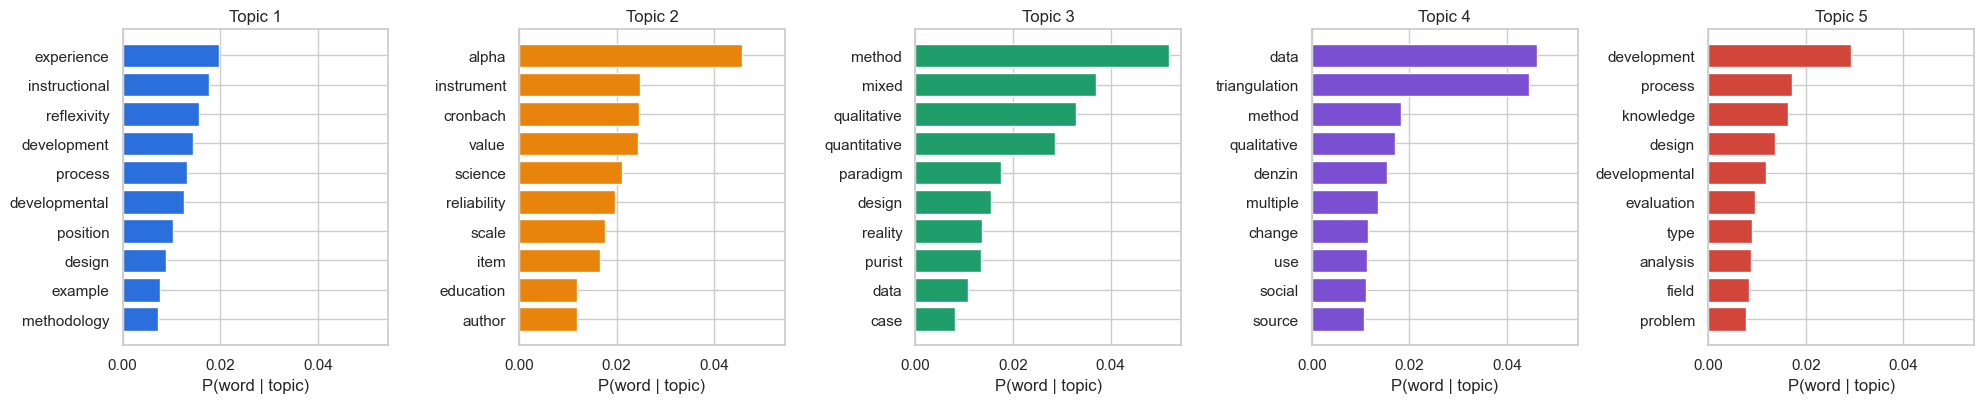

In [17]:
palette = ["#2a6fdb", "#e8830c", "#1f9d6b", "#7a4fd1", "#d1453b"]
fig, axes = plt.subplots(1, N_TOPICS, figsize=(4 * N_TOPICS, 4.2), sharex=True)
for t, ax in enumerate(axes):
    idx = np.argsort(topic_word[t])[::-1][:10][::-1]
    ax.barh(vocab[idx], topic_word[t, idx], color=palette[t])
    ax.set_title(topic_names[t])
    ax.set_xlabel("P(word | topic)")
plt.tight_layout()
plt.show()

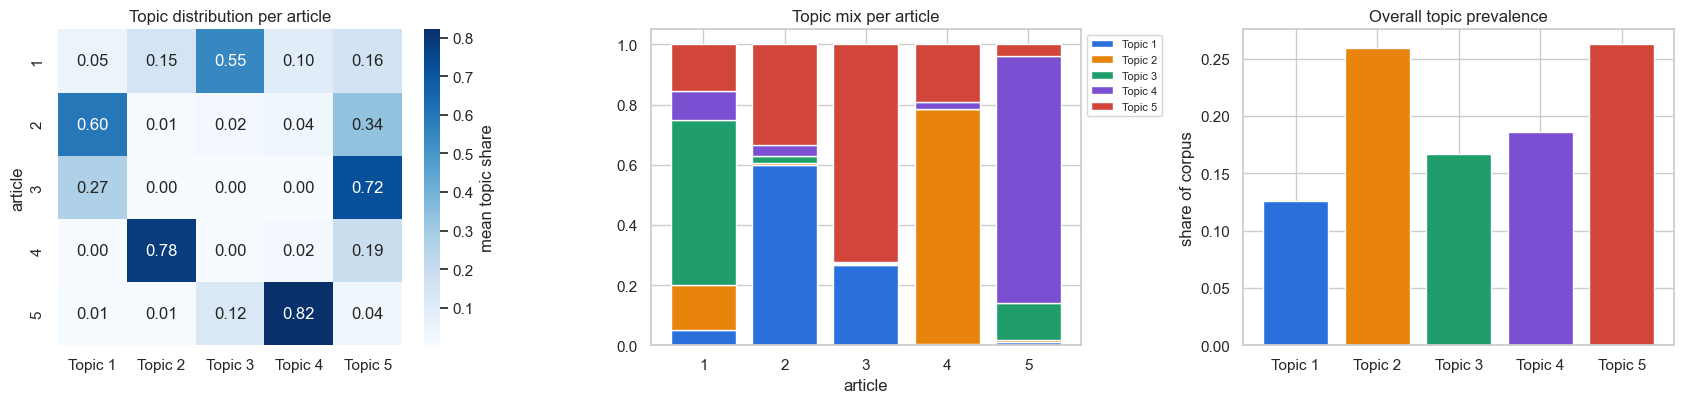

,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5
article_id,,,,,
1,0.05,0.15,0.55,0.10,0.16
2,0.60,0.01,0.02,0.04,0.34
3,0.27,0.00,0.00,0.00,0.72
4,0.00,0.78,0.00,0.02,0.19
5,0.01,0.01,0.12,0.82,0.04


In [18]:
doc_topic = lda.transform(dtm)
doc_topic_df = pd.DataFrame(doc_topic, columns=topic_names)
doc_topic_df["article_id"] = chunks.article_id.values
by_article = doc_topic_df.groupby("article_id")[topic_names].mean()
prevalence = pd.Series(doc_topic.mean(axis=0), index=topic_names)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.heatmap(by_article, annot=True, fmt=".2f", cmap="Blues", ax=ax[0], cbar_kws={"label": "mean topic share"})
ax[0].set_title("Topic distribution per article")
ax[0].set_ylabel("article")
by_article.plot(kind="bar", stacked=True, color=palette, ax=ax[1], width=0.8)
ax[1].set_title("Topic mix per article")
ax[1].set_xlabel("article")
ax[1].tick_params(axis="x", rotation=0)
ax[1].legend(fontsize=8, bbox_to_anchor=(1, 1))
ax[2].bar(prevalence.index, prevalence.values, color=palette)
ax[2].set_title("Overall topic prevalence")
ax[2].set_ylabel("share of corpus")
plt.tight_layout()
plt.show()
by_article.round(2)

In [20]:
#Question 4.2
import pyLDAvis
try:
    import pyLDAvis.lda_model as ldavis
except ImportError:
    import pyLDAvis.sklearn as ldavis

pyLDAvis.enable_notebook()
panel = ldavis.prepare(lda, dtm, cv, mds="tsne", sort_topics=False)
pyLDAvis.save_html(panel, "lda_intertopic_map.html")
panel

PreparedData(topic_coordinates=               x          y  topics  cluster       Freq
topic                                                  
0      -0.159717   4.738980       1        1  11.278342
1     -27.255646 -54.073883       2        1  26.293249
2      35.193310 -27.888668       3        1  18.306828
3     -47.633934 -10.005839       4        1  18.268021
4      16.582933 -74.191719       5        1  25.853560, topic_info=               Term        Freq       Total Category  logprob  loglift
51            alpha  107.000000  107.000000  Default  30.0000  30.0000
1245  triangulation   72.000000   72.000000  Default  29.0000  29.0000
764          method  119.000000  119.000000  Default  28.0000  28.0000
775           mixed   67.000000   67.000000  Default  27.0000  27.0000
298            data  105.000000  105.000000  Default  26.0000  26.0000
...             ...         ...         ...      ...      ...      ...
231         concept   10.294284   32.432028   Topic5  -5.4099   0.2052
1286          value   10.583326   74.903802   Topic5  -5.3823  -0.6042
860      particular    9.169400   22.855219   Topic5  -5.5257   0.4394
1277           used    9.232145   37.972614   Topic5  -5.5188  -0.0615
1265  understanding    9.171897   29.712118   Topic5  -5.5254   0.1773

[317 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
0         2  0.088370     ability
0         4  0.618588     ability
0         5  0.265109     ability
7         2  0.932200  acceptable
19        1  0.113721    activity
...     ...       ...         ...
1315      1  0.825242       women
1316      2  0.104188        word
1316      3  0.625126        word
1316      5  0.208375        word
1322      3  0.826435     writing

[471 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5])